# Import

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import requests

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [ ]:
from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

# Hyperparams

In [ ]:
n_vocab   = 50257
embed_dim = 768
seq_len   = 256
n_heads   = 12
n_blocks  = 12
batch_size= 16
stride    = 4

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Data

In [ ]:
text = requests.get('https://www.gutenberg.org/cache/epub/829/pg829.txt').text
gt_tokens = torch.tensor(tokenizer.encode(text), dtype = torch.long)
len(gt_tokens)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (158340 > 1024). Running this sequence through the model will result in indexing errors


158340

In [ ]:
gt_tokens, len(gt_tokens)

(tensor([  464,  4935, 20336,  ...,   198,   201,   198]), 158340)

# Train test split

In [ ]:
train_ratio = .9

test_split_point = int(train_ratio*len(gt_tokens))

train_data = gt_tokens[:test_split_point]
test_data  = gt_tokens[test_split_point:]

def get_data_batch(training = True):

  # pick the dataset to use
  if training:
      data = train_data
  else:
      data = test_data

  # pick random indices to start
  ix = torch.randint(len(data)-seq_len, size = (batch_size, ))

  # get the data via broadcasting outer product
  X  = gt_tokens[ix[:,None] + torch.arange(seq_len)]
  y  = gt_tokens[ix[:,None] + torch.arange(1, seq_len+1)]

  return X, y

X, y = get_data_batch()
print(f'Input data (size {X.shape}:\n)',X)
print(f'\n\nTargets (size {y.shape}):\n',y)

Input data (size torch.Size([16, 256]):
) tensor([[27287,   262,   845,  ...,   616, 18129,   550],
        [36267,   511,  1751,  ..., 10427,   257,   201],
        [  198,  1169,   649,  ...,   286,   262, 23129],
        ...,
        [ 8117,   389,   523,  ...,   616,  4693,    26],
        [  314,  2582,  5071,  ...,   898, 10135,   287],
        [  319,   428,   201,  ...,  9550,    11,   262]])


Targets (size torch.Size([16, 256])):
 tensor([[  262,   845,   717,  ..., 18129,   550,   925],
        [  511,  1751,    13,  ...,   257,   201,   198],
        [ 1169,   649,   393,  ...,   262, 23129,   447],
        ...,
        [  389,   523,   867,  ...,  4693,    26,  2592],
        [ 2582,  5071,   326,  ..., 10135,   287,  3288],
        [  428,   201,   198,  ...,    11,   262,   976]])


In [ ]:
torch.randint(len(train_data)-seq_len, size = (batch_size, ))[:,None]

tensor([[ 17646],
        [128540],
        [ 47084],
        [ 94098],
        [104120],
        [119596],
        [103775],
        [ 46119],
        [110134],
        [ 45457],
        [ 30923],
        [  3175],
        [ 17199],
        [115008],
        [ 99551],
        [ 76954]])

In [ ]:
torch.arange(seq_len), torch.arange(seq_len).shape

(tensor([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
          14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,
          28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,
          42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,
          56,  57,  58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,
          70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,
          84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,
          98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111,
         112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125,
         126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139,
         140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153,
         154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167,
         168, 169, 170, 171, 172, 173, 174, 175, 176

In [ ]:
res = torch.randint(len(train_data)-seq_len, size = (batch_size, ))[:,None] + torch.arange(seq_len)
res, res.shape

(tensor([[128190, 128191, 128192,  ..., 128443, 128444, 128445],
         [100523, 100524, 100525,  ..., 100776, 100777, 100778],
         [ 98671,  98672,  98673,  ...,  98924,  98925,  98926],
         ...,
         [141083, 141084, 141085,  ..., 141336, 141337, 141338],
         [ 35891,  35892,  35893,  ...,  36144,  36145,  36146],
         [ 43891,  43892,  43893,  ...,  44144,  44145,  44146]]),
 torch.Size([16, 256]))

# Model 5

## MHA + Trans

In [ ]:
class MultiHeadAttention(nn.Module):
  def __init__(self):
    super().__init__()

    # number of attention heads
    self.num_heads = n_heads
    self.head_dim  = embed_dim // n_heads

    # the three Q, K, V weights matrices are initialized as one, and are split inside
    self.QKV = nn.Linear(embed_dim, 3*embed_dim, bias = True)

    # linear mixing after attention
    self.W0 = nn.Linear(embed_dim, embed_dim, bias = True)

  def forward(self, x):

    # sizes for later use
    B, T, E = x.shape # [batch, seq_len, embed_dim]

    # push data through Q, K and V in one concatenated matrix
    qkv = self.QKV(x) # [batch, sequence, 3*embed]
    q, k, v = torch.split(qkv, E, dim = 2) # each matrix is [B,T,E]

    # reshape to [B, T, nHeads, head_dim]
    # and transpose to [B, nHeads, T, head_dim]
    q = q.view(B, T, self.num_heads, self.head_dim).transpose(1,2)
    k = k.view(B, T, self.num_heads, self.head_dim).transpose(1,2)
    v = v.view(B, T, self.num_heads, self.head_dim).transpose(1,2)

    # PyTorch's dot-product attention function handles multi-head shapes
    out = F.scaled_dot_product_attention(q, k, v, is_causal = True)

    # recombine heads: (B, nHeads, T, head_dim) -> [B, T, E]
    out = out.transpose(1,2).view(B,T,E)

    # finally, linearly mix the attention heads
    out = self.W0(out)

    return out

class TransformerBlock(nn.Module):
  def __init__(self):
    super().__init__()

    # attention subblock
    self.layernorm_1 = nn.LayerNorm(embed_dim, eps = 1e-5)
    self.attn = MultiHeadAttention()

    # linear feedforward (MLP) subblock
    self.layernorm_2 = nn.LayerNorm(embed_dim, eps = 1e-5)

    # 4x expansion, then back to embedding size
    self.mlp_1 = nn.Linear(embed_dim, 4* embed_dim, bias = True)
    self.gelu  = nn.GELU()
    self.mlp_2 = nn.Linear(4*embed_dim, embed_dim, bias = True)

  def forward(self, x):

    # attention
    x_att = self.layernorm_1(x) # pre-attention normalization
    x_att = x + self.attn(x_att) # run through attention then add pre-attention

    # MLP
    x_ff = self.layernorm_1(x) # pre-MLP normalization
    x_ff = x_att + self.mlp_2(self.gelu(self.mlp_1(x_ff)))

    return x_ff

In [ ]:
mha = MultiHeadAttention()
transformer_block = TransformerBlock()

## Language Model

In [ ]:
class LanguageModel(nn.Module):
  def __init__(self):
    super().__init__()

    # token + position embeddings
    self.wte = nn.Embedding(n_vocab, embed_dim) # token embedding
    self.wpe = nn.Embedding(seq_len, embed_dim) # position embedding

    # transformer blocks
    self.transformer_blocks= nn.Sequential(*[TransformerBlock() for _ in range(n_blocks)])

    # final layernorm
    self.layernorm_final = nn.LayerNorm(embed_dim, eps = 1e-5)

    # lm head with weights tied to token embeddings
    self.final_head = nn.Linear(embed_dim, n_vocab, bias = False)
    self.final_head.weight = nn.Parameter(self.wte.weight)

  def forward(self, idx):

    # token + position embeddings (note the device!)
    token_emb = self.wte(idx) # [B, T, E]
    posit_emb = self.wpe(torch.arange(idx.shape[-1], device = device)) # [T, E]
    x = token_emb + posit_emb # [B, T, E]

    # pass through each transformer block
    x = self.transformer_blocks(x)

    # final layernorm and unembeddings
    x = self.layernorm_final(x)
    logits = self.final_head(x) # [B, T, n_vocab]

    return F.log_softmax(logits, dim=-1)

  def generate(self, idx, temperature = 1., max_new_tokens = 50):

    for _ in range(max_new_tokens):

      # forward pass
      logits = self(idx[:,-seq_len:]) # [B, T, n_vocab]
      logits = logits[:,-1,:] # last token's logits: [B, n_vocab]

      # apply temperature + softmax
      probs = F.softmax(logits/temperature, dim = -1) # [B, n_vocab]

      # sample next token
      idx_next = torch.multinomial(probs, num_samples = 1) # [B, 1]

      # append
      idx = torch.cat((idx, idx_next), dim = 1) # [B, T+1]

    return idx

## Test

In [ ]:
# create an instance and test with some data
model = LanguageModel().to(device)

X, y = get_data_batch()
X, y = X.to(device), y.to(device)
out = model(X)
print(f'Input size: { X.shape}')
print(f'Output size: {out.shape}')

Input size: torch.Size([16, 256])
Output size: torch.Size([16, 256, 50257])


In [ ]:
# generate new text before any training
start_toks = torch.tensor(tokenizer.encode('The man-mountain shall not depart from')).unsqueeze(0)

# text gen
Y = model.generate(start_toks.to(device), max_new_tokens = 100)
print(tokenizer.decode(Y[0].tolist()).replace('\r','\n'))

The man-mountain shall not depart from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from from


# Loss + Optim

In [ ]:
loss_function = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = .001, weight_decay = .01)

In [ ]:
# check loss function with sizes
X, y = get_data_batch()
X = X[0].unsqueeze(0)
y = y[0].unsqueeze(0)
log_probs = model(X.to(device))

print(f'Model input is size:   {X.shape}')
print(f'Model output is size:  {log_probs.shape}')
print(f'Target tokens is size: {y.shape}')

# flatten as before
log_probs_flat = log_probs.view(-1,log_probs.shape[-1])

# compute the loss
loss = loss_function(log_probs_flat, y.view(-1).to(device)) #.view(-1) flattens to 1 dimension all dimensions present in y [2,3,4] -> [24]
print('\nLoss:', loss.item())

Model input is size:   torch.Size([1, 256])
Model output is size:  torch.Size([1, 256, 50257])
Target tokens is size: torch.Size([1, 256])

Loss: 483.0660400390625


In [ ]:
y.shape, y.view(-1).shape

(torch.Size([1, 256]), torch.Size([256]))

# Train

In [ ]:
num_samples = 501

# initialize losses
train_loss = np.zeros(num_samples)
test_loss  = np.zeros(num_samples)

for sampli in range(num_samples):

  # get a batch of data
  X, y = get_data_batch()

  # move data to GPU
  X, y = X.to(device), y.to(device)

  # clear previous gradients
  model.zero_grad(set_to_none = True)

  # forward pass
  log_probs = model(X)

  # calculate the losses on the (reshaped) final target word
  loss = loss_function(log_probs.view(-1, log_probs.shape[-1]), y.view(-1))

  # backprop
  loss.backward()
  optimizer.step()

  # store the per-sample loss
  train_loss[sampli] = loss.item()

  # evaluate the model with the test set
  if sampli%100 == 0:
    with torch.no_grad():
      X, y = get_data_batch(False) # Fale --> testset data
      X, y = X.to(device), y.to(device) # push it to the GPU
      out = model(X)                    # forward pass
      this_loss = loss_function(out.view(-1, out.shape[-1]), y.view(-1))
      test_loss[sampli] = this_loss.item()

      # update out progress
      print(f'Sample {sampli:4}, train loss: {train_loss[sampli]:.4f}, test loss: {test_loss[sampli]:.4f}')

Sample    0, train loss: 475.5285, test loss: 99.0355
Sample  100, train loss: 12.8549, test loss: 13.1914
Sample  200, train loss: 7.2017, test loss: 7.3680
Sample  300, train loss: 6.5858, test loss: 6.9453
Sample  400, train loss: 6.0429, test loss: 5.9397
Sample  500, train loss: 5.3929, test loss: 5.5369


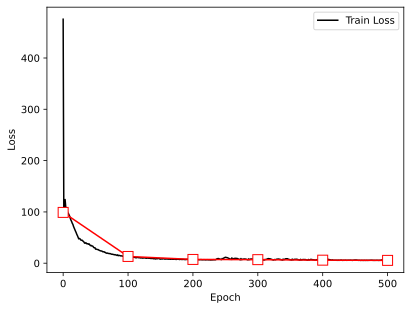

In [ ]:
plt.plot(train_loss, 'k', label = 'Train Loss')
plt.plot(range(0, num_samples, 100), test_loss[::100], 'rs-', markerfacecolor = 'w', markersize = 10)

plt.legend()
plt.gca().set(xlabel='Epoch', ylabel = 'Loss')
plt.show()

In [ ]:
# generate new text
start_toks = torch.tensor(tokenizer.encode('Look around you and think what it would be')).unsqueeze(0)

Y = model.generate(start_toks.to(device), max_new_tokens = 100)
print(tokenizer.decode(Y[0].tolist()).replace('\r','\n'))

Look around you and think what it would be my several pains in for in it would his

Thatliness hisl thoughtamin itself, at the One facts to propagate from the these window; and very joy “that in six earliest debate; but

mist keep; for banging answer, and continent, such external our occasions head, for r considering a already provided to islands, whouh mes quarters of measure another they was who arehouse, because the never never, and that I observed,ure was: anysulate;
